In [60]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [61]:
# Define State
class BMIState(TypedDict):
    weight_kg : float
    height_m : float
    bmi_result : float

In [62]:
def calculate_bmi(state : BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state["height_m"]
    bmi = weight / (height ** 2)

    state["bmi_result"] = round(bmi, 2)
    return state

In [63]:
# Define your graph
graph = StateGraph(BMIState)

In [64]:
# Add nodes to your graph
graph.add_node("calculate_bmi", calculate_bmi)

# Add edges to your graph
graph.add_edge(START, "calculate_bmi")
graph.add_edge("calculate_bmi", END)

In [65]:
# Compile the graph
workflow = graph.compile()

In [66]:
# Execute the graph
initial_state = {"weight_kg" : 70, "height_m" : 1.93}
final_state = workflow.invoke(initial_state)
final_state

{'weight_kg': 70, 'height_m': 1.93, 'bmi_result': 18.79}

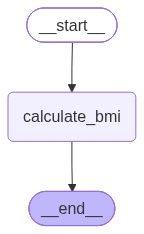

In [67]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())